# Milestone 2: Data Audit, Baseline, and Evaluation Design
**Which survey questions help a primary care provider anticipate reported diabetes? A binary logistic-regression baseline on the UCI CDC Diabetes Health Indicators data**
CAPS-DATASTUDIES 5040, Applied Machine Learning, Fall 2026

Companion files: `README.md` (project summary, data dictionary), `MILESTONE2_REQUIREMENTS.md` (checklist), `requirements.txt`. **All data come from UCI only** (`ucimlrepo`, dataset id 891).

**Order of operations.** The final test set is split off and locked in Section 0.4, *before* any EDA or fitting. Sections 3 to 8 use only the development set. Preprocessing is fitted inside `Pipeline` objects, refit in every cross-validation fold.



## 0. Setup, reproducibility, and data access

### 0.1 Imports, seed, versions

In [2]:
import sys, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             log_loss, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay

SEED = 5040
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Python      :", sys.version.split()[0], "|", platform.platform())
for m in (np, pd, matplotlib, sklearn):
    print(f"{m.__name__:<12}:", m.__version__)

Python      : 3.11.14 | macOS-15.7.7-x86_64-i386-64bit
numpy       : 2.3.5
pandas      : 2.3.3
matplotlib  : 3.10.7
sklearn     : 1.7.2


### 0.2 Load the data (UCI only)
`ucimlrepo.fetch_ucirepo(id=891)` returns an `ID` column, 21 features, and the target `Diabetes_binary`. The raw table is cached in `data/` (git-ignored; never commit data) so reruns do not need the network. Install once if needed: `pip install ucimlrepo`.

In [3]:
DATA = Path("data"); DATA.mkdir(exist_ok=True)
UCI_CACHE = DATA / "cdc_diabetes_uci_raw.csv"

if UCI_CACHE.exists():
    df = pd.read_csv(UCI_CACHE)
else:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=891)
    df = pd.concat([ds.data.ids, ds.data.features, ds.data.targets], axis=1)
    df.to_csv(UCI_CACHE, index=False)

print(df.shape)
df.head()

(253680, 23)


,ID,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3,0
1,1,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1,0
2,2,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8,0
3,3,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6,0
4,4,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4,0


### UCI data description (as provided on the UCI dataset page)
**Source:** UCI Machine Learning Repository, *CDC Diabetes Health Indicators*, Variables table, <https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators> (DOI 10.24432/C53919). The table below was copied from that page by the project author on 2026-10-18 and reformatted from tab-separated text to Markdown; wording is unchanged. The "Demographic" column is shown only where UCI fills it. "Units" is empty for every variable, and UCI reports **no missing values** for any variable.

| Variable name | Role | Type | Demographic | Description |
|---|---|---|---|---|
| ID | ID | Integer | | Patient ID |
| Diabetes_binary | Target | Binary | | 0 = no diabetes 1 = prediabetes or diabetes |
| HighBP | Feature | Binary | | 0 = no high BP 1 = high BP |
| HighChol | Feature | Binary | | 0 = no high cholesterol 1 = high cholesterol |
| CholCheck | Feature | Binary | | 0 = no cholesterol check in 5 years 1 = yes cholesterol check in 5 years |
| BMI | Feature | Integer | | Body Mass Index |
| Smoker | Feature | Binary | | Have you smoked at least 100 cigarettes in your entire life? [Note: 5 packs = 100 cigarettes] 0 = no 1 = yes |
| Stroke | Feature | Binary | | (Ever told) you had a stroke. 0 = no 1 = yes |
| HeartDiseaseorAttack | Feature | Binary | | coronary heart disease (CHD) or myocardial infarction (MI) 0 = no 1 = yes |
| PhysActivity | Feature | Binary | | physical activity in past 30 days - not including job 0 = no 1 = yes |
| Fruits | Feature | Binary | | Consume Fruit 1 or more times per day 0 = no 1 = yes |
| Veggies | Feature | Binary | | Consume Vegetables 1 or more times per day 0 = no 1 = yes |
| HvyAlcoholConsump | Feature | Binary | | Heavy drinkers (adult men having more than 14 drinks per week and adult women having more than 7 drinks per week) 0 = no 1 = yes |
| AnyHealthcare | Feature | Binary | | Have any kind of health care coverage, including health insurance, prepaid plans such as HMO, etc. 0 = no 1 = yes |
| NoDocbcCost | Feature | Binary | | Was there a time in the past 12 months when you needed to see a doctor but could not because of cost? 0 = no 1 = yes |
| GenHlth | Feature | Integer | | Would you say that in general your health is: scale 1-5 1 = excellent 2 = very good 3 = good 4 = fair 5 = poor |
| MentHlth | Feature | Integer | | Now thinking about your mental health, which includes stress, depression, and problems with emotions, for how many days during the past 30 days was your mental health not good? scale 1-30 days |
| PhysHlth | Feature | Integer | | Now thinking about your physical health, which includes physical illness and injury, for how many days during the past 30 days was your physical health not good? scale 1-30 days |
| DiffWalk | Feature | Binary | | Do you have serious difficulty walking or climbing stairs? 0 = no 1 = yes |
| Sex | Feature | Binary | Sex | 0 = female 1 = male |
| Age | Feature | Integer | Age | 13-level age category (_AGEG5YR see codebook) 1 = 18-24 9 = 60-64 13 = 80 or older |
| Education | Feature | Integer | Education Level | Education level (EDUCA see codebook) scale 1-6 1 = Never attended school or only kindergarten 2 = Grades 1 through 8 (Elementary) 3 = Grades 9 through 11 (Some high school) 4 = Grade 12 or GED (High school graduate) 5 = College 1 year to 3 years (Some college or technical school) 6 = College 4 years or more (College graduate) |
| Income | Feature | Integer | Income | Income scale (INCOME2 see codebook) scale 1-8 1 = less than $10,000 5 = less than $35,000 8 = $75,000 or more |

**Points from the documentation that the audit checks or that limit it:**
- `ID` is described as **"Patient ID"** (an identifier of a respondent), which is the basis for treating each row as one respondent (Section 0.4). The documentation does not say how IDs were assigned.
- `Diabetes_binary = 1` is described as "prediabetes or diabetes" (examined in Section 2.4).
- `MentHlth` and `PhysHlth` are documented as "scale 1-30 days", but the data also contain **0** (Section 3.3); 0 is a valid "no bad days" answer, so the documented range is incomplete.
- `Age`, `Education` and `Income` cite the BRFSS codebook variables `_AGEG5YR`, `EDUCA` and `INCOME2`, which is where the exact coding should be verified.
- Only some codes are listed for `Age` (1, 9, 13) and `Income` (1, 5, 8) in the documentation.
- No variable is documented as a survey weight, strata, or primary sampling unit.

### 0.3 Engineer the modeling target
The only label UCI provides is `Diabetes_binary` (0/1). The notebook adds a clearly named column, `diabetes_reported`, that is the modeling target, and keeps the original column untouched for audit.

**What the label means.** UCI's page describes `1` as "prediabetes or diabetes". `1` corresponds to **diabetes only** and that prediabetes respondents are coded `0`. UCI data alone cannot separate prediabetes from no diabetes, so the target here is **reported diabetes**, and prediabetes sits in the reference class (see Sections 1 and 2.4). A three-class target is not obtainable from UCI data.

In [4]:
TARGET = "diabetes_reported"                      # 1 = reported diabetes, 0 = otherwise (see text above)
df[TARGET] = df["Diabetes_binary"].astype(int)
assert set(df[TARGET].unique()) == {0, 1}
LABELS = {0: "no diabetes (incl. prediabetes)", 1: "diabetes"}
feature_cols = [c for c in df.columns if c not in ("ID", "Diabetes_binary", TARGET)]
assert len(feature_cols) == 21
print("features:", len(feature_cols), "| positives:", int(df[TARGET].sum()), f"({df[TARGET].mean():.1%})")

features: 21 | positives: 35346 (13.9%)


### 0.4 Check row identity, then lock the final test set (before any EDA)
**No rows are dropped.** UCI documents `ID` as "Patient ID", so each row is treated as a distinct respondent. Two respondents can give identical answers to 21 mostly yes/no questions, so identical answers are *not* evidence of a repeated person and are not removed (Section 3.2 quantifies them). The check below asks the question that matters: does any `ID` appear twice?

**Limitation.** `ID` is unique and equals the row position (0 to n-1; Section 2.4). That shows no row is repeated, but it cannot show that no *person* appears twice, because the file carries no other respondent link.

The split is stratified on the target. The test set is **not used again** until the final evaluation in a later milestone. Procedure and justification: Section 9.

In [5]:
assert df["ID"].notna().all() and df["ID"].is_unique, "an ID appears more than once"
print(f"ID check passed: {len(df):,} rows, {df['ID'].nunique():,} distinct IDs")

dev, test = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=SEED)
dev = dev.reset_index(drop=True)
test = test.reset_index(drop=True)               # LOCKED: no inspection, no decisions

X_dev, y_dev = dev[feature_cols], dev[TARGET]
N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

print(f"all rows {len(df):,} -> dev {len(dev):,} / test {len(test):,}")

ID check passed: 253,680 rows, 253,680 distinct IDs
all rows 253,680 -> dev 202,944 / test 50,736


## 1. Project continuity and Milestone 1 feedback (10 pts)

### 1.1 Restatement (revised after the audit)
- **Analytical question.** Which self-reported health, lifestyle, demographic, and care-history answers are associated with a respondent's **reported diabetes diagnosis**, and how well do they jointly discriminate it? The aim is research evidence for a **guide for primary care providers (PCPs)**: which questions to ask and which tests to consider when estimating diabetes status without directly testing glucose.

- **Stakeholder and decision.** PCPs and public-health researchers deciding which intake questions and follow-up tests are worth prioritizing. The model output informs that choice; it is not a diagnosis and not an individual patient decision tool.

- **Changes from Milestone 1.** (1) Milestone 1 framed this as a screening tool for people *before* diagnosis; the data only record *reported diagnosis at survey time*, so it is reframed as a research guide. Because the guide serves clinicians who see a patient's history, it is acceptable for features to reflect **prior medical contact** (blood pressure, cholesterol, care access). (2) Milestone 1 assumed the target combined prediabetes and diabetes. A cross-check indicates the UCI label is diabetes only and that prediabetes is coded 0. Prediabetes cannot be separated using UCI data, so it stays in the reference class and the target is **reported diabetes**.

- **Observation.** One respondent in the CDC BRFSS telephone survey.

- **Target.** $y=1$ if the respondent reports a diabetes diagnosis, $y=0$ otherwise (including prediabetes and undiagnosed diabetes). Not future risk and not undiagnosed disease.

- **Use time.** Time of a clinical visit or intake questionnaire, with the patient able to answer the questions and prior results available to the PCP.

- **Generalization objective.** Associations and discrimination for new respondents drawn from the same survey wave and sampling process. Not claimed: other years, clinical populations, causal effects, or population-weighted estimates (Section 9).

### 1.2 Mathematical contract
$$\mathcal{Z}=\mathcal{X}\times\mathcal{Y},\qquad Z=(X,Y),\qquad z_i=(x_i,y_i),\qquad S_n=\{z_i\}_{i=1}^{n}$$

- **Index** $i\in\{1,\dots,n\}$ labels a survey respondent (one row); $n=253{,}680$ in the raw file.
- **Predictors** $x_i\in\mathcal X\subset\mathbb R^{21}$: 21 survey answers (binary indicators, ordinal categories coded as integers, day counts, and BMI).
- **Target** $y_i\in\mathcal Y=\{0,1\}$: reported diabetes (1) versus not (0).
- **Group / time / location index:** none in the file. The survey is a single wave and carries no household, state, or date column, so rows are treated as exchangeable respondents (a stated assumption; see Section 9).
- **Random vs realized vs sample.** $Z$ is a random respondent drawn from the survey process; $z_i$ is the realized record of respondent $i$; $S_n$ is the finite sample. $S_n$ (all rows) is split into development and test samples.

### 1.3 Feedback response matrix
Statuses are as of this notebook. Every Open or Partially resolved row has a next step.

In [29]:
feedback = pd.DataFrame([
 ("Clarify whether the objective is diagnosed vs. undiagnosed vs. future diabetes",
  "Target defined as reported diagnosis at survey time. Undiagnosed and future risk are stated as unsupported. Intended use changed to a PCP research guide.",
  "Sec. 1.1, 9.1", "Resolved"),

 ("Justify combining prediabetes and diabetes; investigate the original target categories",
  "An external cross-check against the original three-class copy found that the UCI binary label is diabetes only (prediabetes coded 0), so the Milestone 1 combined class was never in the file. UCI data cannot separate prediabetes, so the target is binary reported diabetes with prediabetes in the reference class.",
  "Sec. 0.3, 2.4", "Prediabetes versus diabetes cannot be studied with UCI data alone. Decision made to use Binary target. Resolved."),
 
 ("Formalize z_i = (x_i, y_i)", "Notation block with index, x, y, and group/time statement.", "Sec. 1.2", "Resolved"),
 
 ("Investigate variable definitions and coding conventions",
  "Checked every range and binary coding against the dictionary; no out-of-range values. Cannot detect refusals or don't-know codes that were already recoded.",
  "Sec. 2.2, 3.3", "Partially resolved"),
   
 ("State which preprocessing is learned from training data and how leakage is prevented",
  "Fixed vs fitted operations table; Pipeline refit per fold; per-fold fitted state printed.", "Sec. 6, 9.3", "Resolved"),
 
 ("Expand the Workflow Canvas: baseline, candidate methods, preprocessing, metrics", "Canvas v2 with fixed/learned operators.", "Sec. 10.1", "Resolved"),
 
 ("Error costs differ (missed case vs unnecessary follow-up); metrics should reflect it",
  "Primary metrics: PR-AUC and precision at 80% recall, with log loss, Brier and calibration for the probabilities.", "Sec. 8", "Resolved")
 
 ], columns=["Instructor feedback", "Action or justified decision", "Evidence in Milestone 2", "Status"])
pd.set_option("display.max_colwidth", 200)
feedback.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,Instructor feedback,Action or justified decision,Evidence in Milestone 2,Status
0,Clarify whether the objective is diagnosed vs. undiagnosed vs. future diabetes,Target defined as reported diagnosis at survey time. Undiagnosed and future risk are stated as unsupported. Intended use changed to a PCP research guide.,"Sec. 1.1, 9.1",Resolved
1,Justify combining prediabetes and diabetes; investigate the original target categories,"An external cross-check against the original three-class copy found that the UCI binary label is diabetes only (prediabetes coded 0), so the Milestone 1 combined class was never in the file. UCI data cannot separate prediabetes, so the target is binary reported diabetes with prediabetes in the reference class.","Sec. 0.3, 2.4",Prediabetes versus diabetes cannot be studied with UCI data alone. Decision made to use Binary target. Resolved.
2,"Formalize z_i = (x_i, y_i)","Notation block with index, x, y, and group/time statement.",Sec. 1.2,Resolved
3,Investigate variable definitions and coding conventions,Checked every range and binary coding against the dictionary; no out-of-range values. Cannot detect refusals or don't-know codes that were already recoded.,"Sec. 2.2, 3.3",Partially resolved
4,State which preprocessing is learned from training data and how leakage is prevented,Fixed vs fitted operations table; Pipeline refit per fold; per-fold fitted state printed.,"Sec. 6, 9.3",Resolved
5,"Expand the Workflow Canvas: baseline, candidate methods, preprocessing, metrics",Canvas v2 with fixed/learned operators.,Sec. 10.1,Resolved
6,Error costs differ (missed case vs unnecessary follow-up); metrics should reflect it,"Primary metrics: PR-AUC and precision at 80% recall, with log loss, Brier and calibration for the probabilities.",Sec. 8,Resolved


**Open items and next steps**

**Ordinal coding (new).** Age is not monotone at the top end (Section 4.2). Next: compare numeric with one-hot or spline coding.

## 2. Data provenance and structural audit (10 pts)

### 2.1 Provenance
- **Source.** CDC Behavioral Risk Factor Surveillance System (BRFSS), an annual state-based telephone health survey. Obtained from the UCI Machine Learning Repository ([id 891](https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators), DOI 10.24432/C53919). The creators are not listed on the UCI page.
- **Collection period.** UCI's page says 2014. 
- **Measurement and labeling.** Every column is a **self-reported** answer to a telephone interviewer. The diabetes label comes from the respondent's report of having been told by a health professional that they have diabetes. There is no laboratory or clinical measurement in the file. BMI is computed from self-reported height and weight. Age is pre-bucketed into 13 categories.
- **Preparation by the distributors.** The distributors selected 21 variables, recoded most to 0/1, and removed missing values (UCI reports none). Their exact filtering rules are not documented, so the rows are a *selected* subset of the survey.
- **Sensitive fields.** Sex, income, and education are flagged sensitive by UCI. They are treated as ordinary predictors here, with the caveat in Section 5.
- **Merge.** None. One table from one source.

### 2.2 Dataset inventory
Computed on the full raw file for description only; no modeling decisions are taken from it.

In [7]:
inventory = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
    "mean": df.mean(numeric_only=True).round(3),
})
print(f"rows={len(df):,}  cols={df.shape[1]}  memory={df.memory_usage(deep=True).sum()/1e6:.1f} MB")
inventory

rows=253,680  cols=24  memory=48.7 MB


,dtype,n_unique,min,max,mean
ID,int64,253680,0,253679,126839.500
HighBP,int64,2,0,1,0.429
HighChol,int64,2,0,1,0.424
CholCheck,int64,2,0,1,0.963
BMI,int64,84,12,98,28.382
Smoker,int64,2,0,1,0.443
Stroke,int64,2,0,1,0.041
HeartDiseaseorAttack,int64,2,0,1,0.094
PhysActivity,int64,2,0,1,0.757
Fruits,int64,2,0,1,0.634


### 2.3 Data dictionary
Coding follows the UCI documentation quoted in Section 0.2; intermediate `Age` and `Income` codes (not listed by UCI) follow the BRFSS category order. Availability is the time the answer would be known to a PCP at a visit. The exact BRFSS question wording is not in the UCI files and should be confirmed against the CDC codebook.

In [8]:
data_dictionary = pd.DataFrame([
 (TARGET, "Reported diabetes (engineered target)", "binary", "survey time", "1 = Diabetes_binary 1; 0 otherwise. Prediabetes is in 0 (see 2.4)"),
 ("Diabetes_binary", "UCI label (kept for audit, not a feature)", "binary", "survey time", "UCI text: prediabetes or diabetes; external check: diabetes only"),
 ("ID", "Row identifier", "integer", "n/a", "Sequential index; excluded from features"),
 ("HighBP", "Ever told high blood pressure", "binary", "history / prior test", "1 = yes"),
 ("HighChol", "Ever told high cholesterol", "binary", "history / prior test", "1 = yes"),
 ("CholCheck", "Cholesterol checked in past 5 years", "binary", "history", "1 = yes"),
 ("BMI", "Body mass index", "integer", "asked or measured at visit", "Computed from self-reported height and weight"),
 ("Smoker", "Smoked at least 100 cigarettes in lifetime", "binary", "intake question", "1 = yes"),
 ("Stroke", "Ever told had a stroke", "binary", "history", "1 = yes"),
 ("HeartDiseaseorAttack", "Coronary heart disease or myocardial infarction", "binary", "history", "1 = yes"),
 ("PhysActivity", "Physical activity in past 30 days (not job)", "binary", "intake question", "1 = yes"),
 ("Fruits", "Fruit 1+ times per day", "binary", "intake question", "1 = yes"),
 ("Veggies", "Vegetables 1+ times per day", "binary", "intake question", "1 = yes"),
 ("HvyAlcoholConsump", "Heavy drinker (men >14, women >7 drinks/week)", "binary", "intake question", "1 = yes"),
 ("AnyHealthcare", "Has any health care coverage", "binary", "intake question", "1 = yes"),
 ("NoDocbcCost", "Could not see doctor in past 12 months due to cost", "binary", "intake question", "1 = yes"),
 ("GenHlth", "Self-rated general health", "ordinal 1-5", "intake question", "1 excellent ... 5 poor"),
 ("MentHlth", "Days of poor mental health, past 30 days", "integer 0-30", "intake question", "Day count; UCI says 1-30 but 0 occurs (Sec. 3.3)"),
 ("PhysHlth", "Days of poor physical health, past 30 days", "integer 0-30", "intake question", "Day count; UCI says 1-30 but 0 occurs (Sec. 3.3)"),
 ("DiffWalk", "Serious difficulty walking or climbing stairs", "binary", "intake question", "1 = yes"),
 ("Sex", "Sex", "binary", "intake", "0 female, 1 male"),
 ("Age", "Age category", "ordinal 1-13", "intake", "1 = 18-24, 2 = 25-29, ..., 12 = 75-79, 13 = 80+"),
 ("Education", "Highest education", "ordinal 1-6", "intake question", "1 never/kindergarten only ... 6 college graduate"),
 ("Income", "Household income bracket", "ordinal 1-8", "intake question", "1 under $10k ... 8 $75k or more"),
], columns=["variable", "meaning", "type", "availability at visit", "coding notes"])
assert set(feature_cols) <= set(data_dictionary["variable"]), "dictionary is missing a feature"
data_dictionary

,variable,meaning,type,availability at visit,coding notes
0,diabetes_reported,Reported diabetes (engineered target),binary,survey time,1 = Diabetes_binary 1; 0 otherwise. Prediabetes is in 0 (see 2.4)
1,Diabetes_binary,"UCI label (kept for audit, not a feature)",binary,survey time,UCI text: prediabetes or diabetes; external check: diabetes only
2,ID,Row identifier,integer,n/a,Sequential index; excluded from features
3,HighBP,Ever told high blood pressure,binary,history / prior test,1 = yes
4,HighChol,Ever told high cholesterol,binary,history / prior test,1 = yes
5,CholCheck,Cholesterol checked in past 5 years,binary,history,1 = yes
6,BMI,Body mass index,integer,asked or measured at visit,Computed from self-reported height and weight
7,Smoker,Smoked at least 100 cigarettes in lifetime,binary,intake question,1 = yes
8,Stroke,Ever told had a stroke,binary,history,1 = yes
9,HeartDiseaseorAttack,Coronary heart disease or myocardial infarction,binary,history,1 = yes


### 2.4 Structural checks: is a row a respondent


**What the audit can and cannot show.** Inside the UCI data, `Diabetes_binary` has 218,334 zeros and 35,346 ones (13.9%), and nothing else in the file says what the ones contain. UCI's page describes them as "prediabetes or diabetes".


**Consequence.** The Milestone 1 plan to combine prediabetes and diabetes cannot be implemented from UCI data: the combined class is not in the file, and prediabetes cannot be separated from "no diabetes". The target is therefore **reported diabetes** (`diabetes_reported`), with prediabetes in the reference class. That changes what class 0 means (healthy, prediabetic, or undiagnosed), which matters for every interpretation below.

## 3. Data quality and missingness audit (12 pts)

$$\hat m_j=\frac1n\sum_{i=1}^n \mathbb 1\{x_{ij}\text{ is missing}\}$$

### 3.1 Missingness

In [10]:
miss = pd.DataFrame({"missing_count": df.isna().sum(), "missing_share": df.isna().mean()})
print("Columns with any NaN:", int((miss.missing_count > 0).sum()), "of", len(miss))
miss.sort_values("missing_count", ascending=False).head(5)

Columns with any NaN: 0 of 24


,missing_count,missing_share
ID,0,0.0
HighBP,0,0.0
HighChol,0,0.0
CholCheck,0,0.0
BMI,0,0.0


**Interpretation.** No missing value in any column, consistent with UCI's "no missing values". 

**Consequence:** no imputation is needed, and the imputer in the pipeline is a no-op safeguard for new data. 

**Limitation:** how respondents were selected into the file is unobserved.

### 3.2 Repeated rows and identical answer profiles
Descriptive only: **no rows are removed**. Each row has a distinct `ID`; the question is how many rows share the same 21 answers (and label) with another respondent.

In [31]:
key = feature_cols + [TARGET]
dup_extra = df.duplicated(subset=key)
print(f"IDs repeated: {int(df['ID'].duplicated().sum())}")
print(f"rows whose 21 answers and label match an earlier row (different ID): {dup_extra.sum():,} ({dup_extra.mean():.1%})")

print(f"\nfeature profiles that appear with more than one label: {(nuniq > 1).sum():,}")
print(f"rows belonging to those profiles: {df.merge(nuniq[nuniq > 1].rename('k').reset_index()[feature_cols], on=feature_cols).shape[0]:,}")


IDs repeated: 0
rows whose 21 answers and label match an earlier row (different ID): 24,206 (9.5%)

feature profiles that appear with more than one label: 1,566
rows belonging to those profiles: 5,218


**Interpretation.** Every row has a distinct `ID`, so no row is repeated. 9.5% of rows (24,206) nevertheless share all 21 answers and the label with another respondent. They are concentrated in the reference class: 11.0% of "no diabetes" rows versus 0.7% of diabetes rows. 

 Separately, 1,566 answer profiles (5,218 rows) appear with both labels: identical answers, different diagnosis. That is irreducible noise for any model using these features and puts a ceiling on achievable performance.



### 3.3 Invalid values and implausible ranges

plausible ranges are from data source documentation

In [ ]:
expected = {"Age": (1, 13), "GenHlth": (1, 5), "Education": (1, 6), "Income": (1, 8),
            "MentHlth": (0, 30), "PhysHlth": (0, 30)}

binary_cols = [c for c in feature_cols if c not in expected and c != "BMI"] + [TARGET]
rows = [(c, f"{lo}-{hi}", int(((df[c] < lo) | (df[c] > hi)).sum())) for c, (lo, hi) in expected.items()]
rows += [(c, "{0,1}", int((~df[c].isin([0, 1])).sum())) for c in binary_cols]
rng = pd.DataFrame(rows, columns=["column", "expected", "n_out_of_range"])
print("total out-of-range cells:", rng.n_out_of_range.sum())
print("integer-valued everywhere:", bool((df[feature_cols] % 1 == 0).all().all()))
rng[rng.n_out_of_range > 0] if rng.n_out_of_range.any() else rng.head(8)

total out-of-range cells: 0
integer-valued everywhere: True


,column,expected,n_out_of_range
0,Age,1-13,0
1,GenHlth,1-5,0
2,Education,1-6,0
3,Income,1-8,0
4,MentHlth,0-30,0
5,PhysHlth,0-30,0
6,HighBP,"{0,1}",0
7,HighChol,"{0,1}",0


**Interpretation.** No out-of-range cell by the ranges used here

**Documentation discrepancy.** UCI documents `MentHlth` and `PhysHlth` as "scale 1-30 days", but both contain 0 (about 69% and 63% of development respondents). A value of 0 is a sensible "no bad days" answer, so the data range 0-30 is used and the documented range is incomplete. **Limitation:** this confirms the recoded values are valid, not that they are correct (for example, a misreported weight is invisible).

### 3.4 Outliers: BMI and day counts (development set)

count    202944.00
mean         28.38
std           6.60
min          12.00
25%          24.00
50%          27.00
75%          31.00
max          98.00

BMI > 60: 640 | BMI < 15: 60
MentHlth: share at 0 days = 0.69, share at 30 days = 0.05
PhysHlth: share at 0 days = 0.63, share at 30 days = 0.08


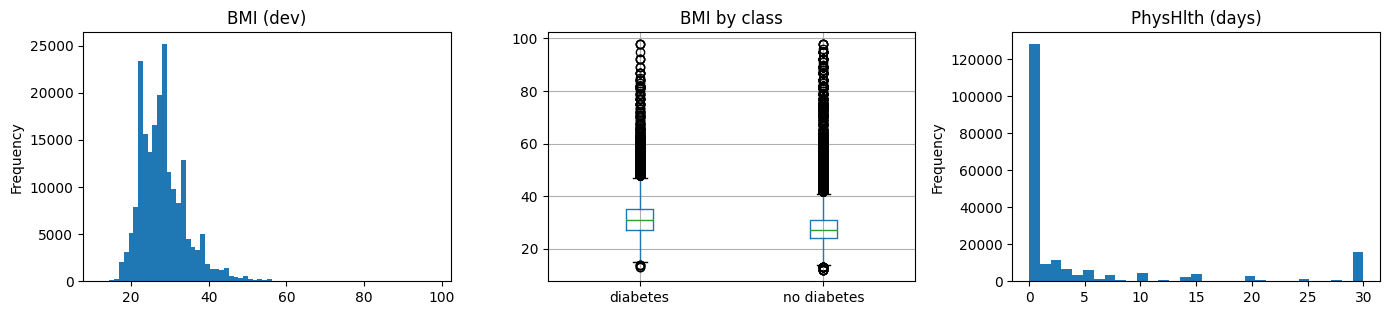

In [13]:
print(dev["BMI"].describe().round(2).to_string())
print("\nBMI > 60:", int((dev.BMI > 60).sum()), "| BMI < 15:", int((dev.BMI < 15).sum()))
for c in ["MentHlth", "PhysHlth"]:
    print(f"{c}: share at 0 days = {(dev[c]==0).mean():.2f}, share at 30 days = {(dev[c]==30).mean():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
dev["BMI"].plot.hist(bins=70, ax=ax[0], title="BMI (dev)")
dev.assign(cls=dev[TARGET].map({0: "no diabetes", 1: "diabetes"})).boxplot("BMI", by="cls", ax=ax[1]); ax[1].set_title("BMI by class"); ax[1].set_xlabel("")
dev["PhysHlth"].plot.hist(bins=31, ax=ax[2], title="PhysHlth (days)")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Interpretation.** BMI is right-skewed (median 27, maximum 98); 640 development rows exceed 60 and 60 fall below 15. Values this extreme are rare and probably include entry or self-report error, but they cannot be told apart from true values. Diabetes respondents have higher BMI overall. The day-count items are U-shaped: 69% report 0 poor mental-health days and 5% report all 30; 63% report 0 poor physical-health days and 8% report all 30. A linear term is a crude summary of such items.

**Treatment.** No clipping or dropping (Section 6.3); standardization is mildly affected by the BMI tail, which is accepted for a baseline. Next: a sensitivity check with winsorized BMI.

### 3.5 Label availability and class balance

In [14]:
bal = pd.concat({"full raw": df[TARGET].value_counts().sort_index(),
                 "dev": dev[TARGET].value_counts().sort_index(),
                 "test": test[TARGET].value_counts().sort_index()}, axis=1)
bal.index = [LABELS[i] for i in bal.index]
prev = (bal / bal.sum()).round(4).add_suffix(" share")
pd.concat([bal, prev], axis=1)

,full raw,dev,test,full raw share,dev share,test share
no diabetes (incl. prediabetes),218334,174667,43667,0.8607,0.8607,0.8607
diabetes,35346,28277,7069,0.1393,0.1393,0.1393


**Interpretation.** Every row has a label. Class shares are 86.1% (no diabetes or prediabetes) and 13.9% (diabetes), identical in development and test after stratification.

**Consequences.** Diabetes is about 1 in 7, so accuracy is uninformative and PR-AUC against a chance level of 0.139 is the honest scale. Class 0 mixes healthy, prediabetic and undiagnosed respondents, so some "negatives" are not negatives in any clinical sense.

**Treatments and limitations.** No rows are excluded, no values are imputed, and no outliers are handled. Group, time and source coverage cannot be audited because the file is one wave with no such columns. Selection into the file, self-report error and label noise (3.2) limit what any model can show.

## 4. Exploratory data analysis (8 pts)
Development set only. Each analysis states the question, finding, implication, and an association-versus-causation note.

### 4.1 Class distribution and prevalence
**Question.** How imbalanced is the target, and what does that mean for metrics?

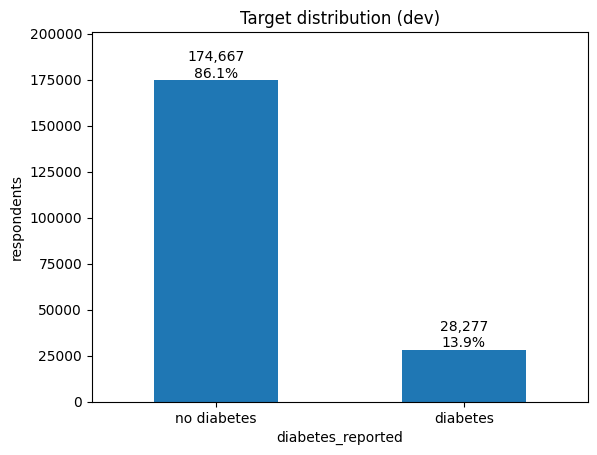

In [15]:
cls = y_dev.map({0: "no diabetes", 1: "diabetes"}).value_counts().reindex(["no diabetes", "diabetes"])
ax = cls.plot.bar(title="Target distribution (dev)", rot=0)
for i, v in enumerate(cls): ax.text(i, v, f"{v:,}\n{v/len(dev):.1%}", ha="center", va="bottom")
ax.set_ylabel("respondents"); ax.set_ylim(0, cls.max() * 1.15); plt.show()

**Finding.** 86.1% no diabetes (including prediabetes) and 13.9% diabetes in the development set.

**Implication.** Metrics must be prevalence-aware: chance PR-AUC is 0.139 and always predicting "no diabetes" is 86.1% accurate. Stratified folds keep about 5,650 diabetes respondents in every validation fold.

**Association vs. causation.** Descriptive only. The positive class is people who report being *told* they have diabetes; undiagnosed diabetes is in class 0.

### 4.2 Diabetes rate across ordered predictors
**Question.** Does the diabetes rate change monotonically with age, self-rated health, income, and BMI? This tests whether treating the ordinal codes as numbers is reasonable in a linear-in-log-odds model.

/var/folders/v6/btzrz7511qx9cdvpgy_f9mzh0000gn/T/ipykernel_65777/3780785280.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dev[TARGET].groupby(bmi_bin).mean().plot(marker="o", ax=axes[3], title="P(diabetes) by BMI band")


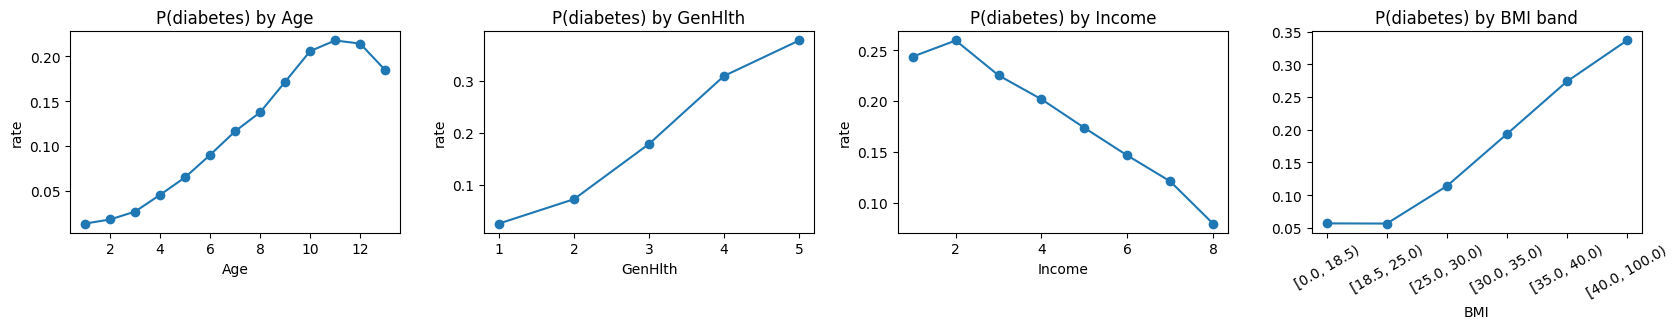

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, c in zip(axes[:3], ["Age", "GenHlth", "Income"]):
    dev[TARGET].groupby(dev[c]).mean().plot(marker="o", ax=ax, title=f"P(diabetes) by {c}")
    ax.set_ylabel("rate")
bmi_bin = pd.cut(dev["BMI"], [0, 18.5, 25, 30, 35, 40, 100], right=False)
dev[TARGET].groupby(bmi_bin).mean().plot(marker="o", ax=axes[3], title="P(diabetes) by BMI band")
axes[3].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Finding.** The diabetes rate rises steeply with self-rated general health (about 3% for excellent to about 38% for poor) and with BMI band (about 6% below 25 to about 34% at 40 and above), and falls with income (about 24-26% in the two lowest brackets to about 8% in the highest). By age it rises to a plateau of about 22% in categories 11-12 (70-79) and then declines to about 19% at 80+.

**Implication.** Treating GenHlth, BMI and Income as linear terms is reasonable. Age is not monotone at the top end, so the linear age term is an approximation (diagnosis timing or survival is one possible explanation; not tested).



### 4.3 Binary predictors versus the target
**Question.** Which yes/no answers shift the diabetes rate most, and are the biggest ones the comorbidity or care-contact variables flagged in Milestone 1?

,P(y=1 | x=0),P(y=1 | x=1),share with x=1,risk ratio
CholCheck,0.025,0.144,0.963,5.770
HighBP,0.060,0.245,0.428,4.094
DiffWalk,0.105,0.309,0.169,2.953
HeartDiseaseorAttack,0.119,0.331,0.094,2.777
HighChol,0.081,0.219,0.424,2.720
Stroke,0.132,0.321,0.041,2.438
Smoker,0.120,0.163,0.443,1.354
NoDocbcCost,0.136,0.173,0.084,1.270
AnyHealthcare,0.117,0.140,0.951,1.198
Sex,0.130,0.152,0.441,1.169


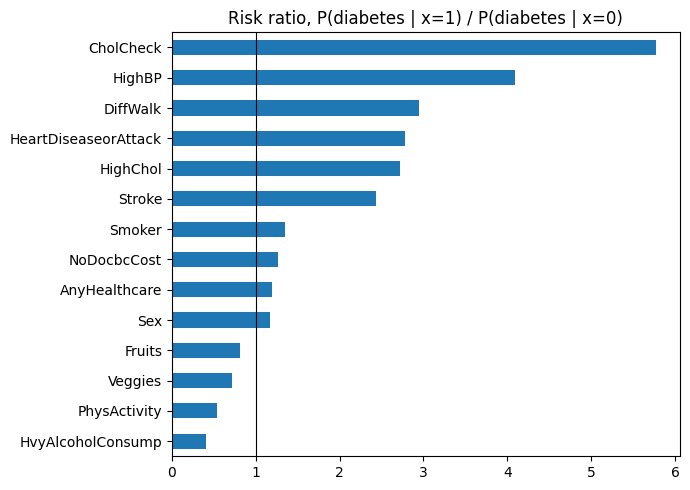

In [17]:
bin_feats = [c for c in feature_cols if dev[c].nunique() == 2]
rr = pd.DataFrame({
    c: {"P(y=1 | x=0)": dev.loc[dev[c] == 0, TARGET].mean(),
        "P(y=1 | x=1)": dev.loc[dev[c] == 1, TARGET].mean(),
        "share with x=1": dev[c].mean()} for c in bin_feats}).T
rr["risk ratio"] = rr["P(y=1 | x=1)"] / rr["P(y=1 | x=0)"]
rr = rr.sort_values("risk ratio", ascending=False)
display(rr.round(3))
rr["risk ratio"].iloc[::-1].plot.barh(figsize=(7, 5), title="Risk ratio, P(diabetes | x=1) / P(diabetes | x=0)")
plt.axvline(1, color="k", lw=0.8); plt.tight_layout(); plt.show()

**Finding.** Largest risk ratios: CholCheck 5.77 (diabetes rate 14.4% with a cholesterol check in the past 5 years versus 2.5% without), HighBP 4.09, DiffWalk 2.95, HeartDiseaseorAttack 2.78, HighChol 2.72, Stroke 2.44. Lowest: HvyAlcoholConsump 0.40, PhysActivity 0.54, Veggies 0.72.

**Implication.** The Milestone 1 worry is confirmed: the strongest signals are comorbidity and **care-contact** variables. CholCheck is the clearest case. 96% of respondents had a check, and the roughly 4% without one are far less likely to carry a diagnosis, which is what a diagnosis-based label produces for unscreened people; it says little about their true glucose status. Heavy drinking looks protective, which is plausibly a "sick-quitter" (reverse-causation) pattern rather than a benefit.

**Next steps for milestone 3** Since we want this test to be a non invasive guide for PCPs to ask patients about their history we could exclude cholesterol depending on the question, is it "have you been told you have high cholesterol?" because then yes it it valid, or is it a blood test result that we would not have at the time of questioning. Either way it could be an argument to remove this indicator because the cholesterol test is a blood test and invasive

### 4.4 Association among predictors
**Question.** Are predictors strongly collinear (a concern for interpreting logistic coefficients)?

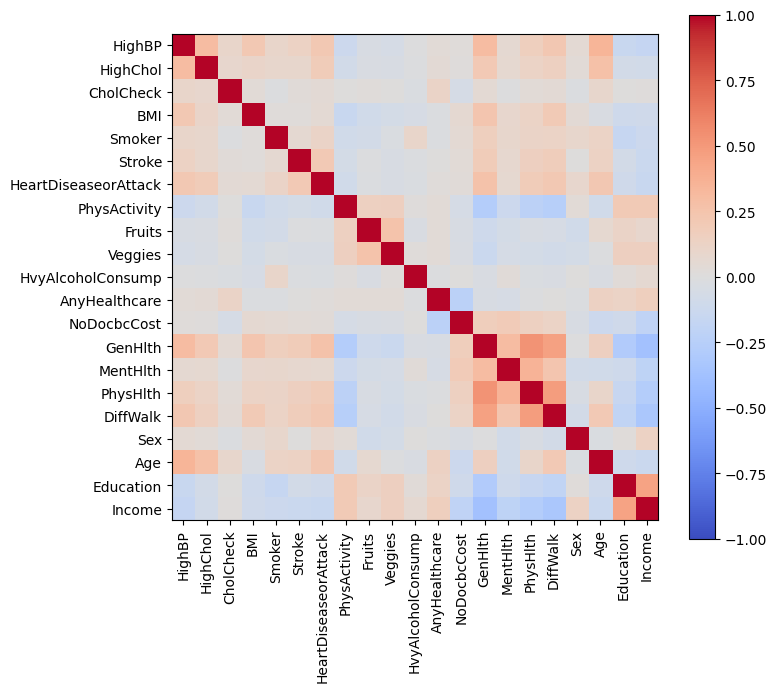

GenHlth    PhysHlth    0.53
PhysHlth   DiffWalk    0.48
GenHlth    DiffWalk    0.46
Education  Income      0.45
GenHlth    Income      0.37
dtype: float64

In [18]:
corr = X_dev.corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
plt.colorbar(im); plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().abs().sort_values(ascending=False).head(5)
pairs.round(2)

**Finding.** Predictors are mostly weakly correlated. The strongest pairs are GenHlth-PhysHlth (0.53), PhysHlth-DiffWalk (0.48), GenHlth-DiffWalk (0.46), Education-Income (0.45) and GenHlth-Income (0.37).

**Implication.** No pair is near collinear.



## 5. Leakage and feature availability assessment (10 pts)

**Information boundary for a non-temporal task.** The boundary here is not a date; it is *what is known to the PCP at the visit versus what is a consequence of already having the diagnosis*. Two cases differ:
- Variables available at a visit that would be asked or looked up *regardless* of diabetes (age, lifestyle, BMI).
- Variables that may exist **because** diabetes was diagnosed (more blood-pressure and cholesterol checks, worse self-rated health or mobility, care contact). They are not leakage in the sense of using the future, but they are *downstream* of the label, so a high score from them means "already known to the health system", not "detectable early".

Under the revised intended use, prior medical contact is allowed. The consequence is an interpretation limit: scores measure association with reported status given a patient's history, not early detection.

For every operation we ask what information it observes, what state it learns, and whether that is available at prediction time.

In [34]:
leakage = pd.DataFrame([
 ("Diabetes_binary", "n/a", "Identical to the target column. Perfect leak if used as a feature.", "Exclude (never a feature)"),
 ("HighBP, HighChol", "Before: history or prior test", "Comorbid with diabetes; more likely recorded after contact with care. Dependency, not future information.", "Retain; effect measured in Sec. 7.6"),
 ("CholCheck, AnyHealthcare, NoDocbcCost", "Before: care-contact history", "Proxy for healthcare access and testing frequency, which affects whether diabetes is diagnosed (so what the label means).", "Retain; flagged group in Sec. 7.6"),
 ("GenHlth, PhysHlth, MentHlth, DiffWalk", "At visit (self-report)", "May be partly a consequence of diabetes; self-report error.", "Retain; effect measured in Sec. 7.6"),
 ("Stroke, HeartDiseaseorAttack", "Before: history", "Complications and comorbidities; may follow diabetes in time.", "Retain; flagged"),
 ("BMI", "At visit (measured or self-reported)", "Self-reported height and weight; weight may change after diagnosis. No future information.", "Retain"),
 ("Smoker, PhysActivity, Fruits, Veggies, HvyAlcoholConsump", "At visit (self-report)", "Self-report and social-desirability error. None identified otherwise.", "Retain"),
 ("Age, Sex, Education, Income", "At visit", "Sensitive attributes; associations may reflect structural factors rather than biology. No leakage.", "Retain; interpret with care"),
], columns=["feature / group", "availability at use time", "leakage or dependency risk", "decision / evidence"])
leakage.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,feature / group,availability at use time,leakage or dependency risk,decision / evidence
0,Diabetes_binary,n/a,Identical to the target column. Perfect leak if used as a feature.,Exclude (never a feature)
1,"HighBP, HighChol",Before: history or prior test,"Comorbid with diabetes; more likely recorded after contact with care. Dependency, not future information.",Retain; effect measured in Sec. 7.6
2,"CholCheck, AnyHealthcare, NoDocbcCost",Before: care-contact history,"Proxy for healthcare access and testing frequency, which affects whether diabetes is diagnosed (so what the label means).",Retain; flagged group in Sec. 7.6
3,"GenHlth, PhysHlth, MentHlth, DiffWalk",At visit (self-report),May be partly a consequence of diabetes; self-report error.,Retain; effect measured in Sec. 7.6
4,"Stroke, HeartDiseaseorAttack",Before: history,Complications and comorbidities; may follow diabetes in time.,Retain; flagged
5,BMI,At visit (measured or self-reported),Self-reported height and weight; weight may change after diagnosis. No future information.,Retain
6,"Smoker, PhysActivity, Fruits, Veggies, HvyAlcoholConsump",At visit (self-report),Self-report and social-desirability error. None identified otherwise.,Retain
7,"Age, Sex, Education, Income",At visit,Sensitive attributes; associations may reflect structural factors rather than biology. No leakage.,Retain; interpret with care


**Still needs verification.**
1. Exact BRFSS wording and time frame of each item (for example, whether HighBP and HighChol mean "ever told" or "told on more than one visit"). Source: CDC codebook; UCI cites the BRFSS variables `_AGEG5YR`, `EDUCA` and `INCOME2` for `Age`, `Education` and `Income`.

**Decisions summary.** Only `ID` and `Diabetes_binary` are excluded as features. The remaining dependency risks are interpretive, so they are measured with the Section 7.6 group analysis rather than excluded, consistent with the revised intended use.

## 6. Preprocessing and feature preparation (10 pts)

### 6.1 Deterministic versus fitted operations
| Operation | Type | State learned | Fitting set |
|---|---|---|---|
| Engineer `diabetes_reported` from `Diabetes_binary` | deterministic | none | n/a |
| Drop `ID` and `Diabetes_binary` from features | deterministic | none | n/a |
| Assert `ID` is unique (no rows dropped) | deterministic | none | n/a |
| Range and coding checks (Section 3.3, nothing needed fixing) | deterministic | none | n/a |
| Median imputation of numeric columns | **fitted** (no-op here: no missing values; kept as a safeguard for new data) | training medians | training fold only |
| Standardize numeric and ordinal columns | **fitted** | $\hat\mu_j,\hat\sigma_j$ | training fold only |
| Pass through binary columns unchanged | deterministic | none | n/a |
| Group selection for the Section 7.6 analysis | deterministic (chosen before fitting) | none | n/a |

### 6.2 Formal statement
$$\hat\eta=\mathrm{Fit}_T(S_{tr}),\qquad x'=T_{\hat\eta}(x)$$

with, for each scaled column $j$,
$$\hat\mu_j=\frac1{n_{tr}}\sum_{i\in\mathcal I_{tr}}x_{ij},\qquad \hat\sigma_j=\sqrt{\frac1{n_{tr}}\sum_{i\in\mathcal I_{tr}}(x_{ij}-\hat\mu_j)^2},\qquad x'_{ij}=\frac{x_{ij}-\hat\mu_j}{\hat\sigma_j}$$

**Zero-variance rule.** If $\hat\sigma_j=0$ in a training fold, `StandardScaler` uses scale 1, so the column becomes $x_{ij}-\hat\mu_j=0$ rather than dividing by zero. No numeric column has zero variance in this data.

**Validation and test inputs** are transformed with the already-fitted $T_{\hat\eta}$ and never refit.

### 6.3 Design decisions
- **Ordinal codes (`Age`, `GenHlth`, `Education`, `Income`) are treated as numeric.** This assumes a monotone, roughly linear effect on the log-odds per step. Section 4.2 supports it for general health, BMI, and (mostly) income, but **not fully for age**, whose diabetes rate peaks at the 70-74 category and then declines. The linear age term is therefore an approximation; a later milestone could replace the ordinal codes with one-hot or spline terms.
- **No clipping of BMI or day counts.** Extreme values are plausible self-reports (Section 3.4) and the model is not tail-sensitive enough to justify a data-dependent cap.
- **Binary columns are not scaled**, to keep their coefficients interpretable as log-odds shifts.

In [ ]:
NUMERIC = ["BMI", "MentHlth", "PhysHlth", "Age", "GenHlth", "Education", "Income"]
BINARY = [c for c in feature_cols if c not in NUMERIC]

def make_preprocessor(cols):
    num = [c for c in NUMERIC if c in cols]
    binr = [c for c in BINARY if c in cols]
    return ColumnTransformer(
        
        [("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("scale", StandardScaler())]), num),
         ("bin", "passthrough", binr)],
        remainder="drop")

def make_pipe(clf, cols=feature_cols):
    return Pipeline([("prep", make_preprocessor(cols)), ("clf", clf)])



## 7. Baseline model and initial results (10 pts)

### 7.1 Formal statement
$$\hat\theta=\mathrm{Fit}_f\big(\{(T_{\hat\eta}(x_i),y_i):i\in\mathcal I_{tr}\}\big),\qquad \hat M(x)=f_{\hat\theta}(T_{\hat\eta}(x)),\qquad \hat p(x)=\Pr(y=1\mid x)$$

The model output is a **probability** of reported diabetes; labels come from a threshold only for the confusion matrices. Preprocessing state $\hat\eta$ (medians, means, scales) is estimated separately from model parameters $\hat\theta$ (coefficients and intercept).

### 7.2 Choice of baselines
- **Dummy (prior).** Predicts the training prevalence for everyone. Any useful model must beat it. Its PR-AUC equals the prevalence, which anchors the metric scale.
- **Binary logistic regression.** Linear in the log-odds, the model the project set out to use, interpretable, and a fair baseline for a mostly binary feature set. L2-regularized maximum likelihood (`C=1`, scikit-learn default).
- **Logistic regression with `class_weight="balanced"`.** Compared once for imbalance handling. No other tuning.

### 7.3 Assumptions
1. Respondents are exchangeable and approximately independent (no household/state structure is visible; not verifiable).
2. Log-odds are linear in the (standardized) features, including the ordinal codes.
3. All rows have equal weight (no survey weights are available).
4. The label noise from self-report is not modeled.

### 7.4 Evaluation code
Cross-validation is written out by hand so that the fold contract is explicit: in each fold a **fresh clone** of the pipeline is fit on the training rows, then used only to predict the validation rows. The metric code is defined first (Section 8 explains the choices).

## 8. Primary evaluation metrics (10 pts)

**The decision.** A PCP guide values finding people who have the condition (a missed case is costly) while keeping the list of people sent for extra questions or tests manageable (false positives cost time and anxiety). With a minority class, accuracy is misleading: always predicting "no diabetes" would be roughly 85% accurate and find nobody.

$$\mathrm{Precision}=\frac{TP}{TP+FP},\qquad \mathrm{Recall}=\frac{TP}{TP+FN}$$

| Metric | What it evaluates | Why chosen |
|---|---|---|
| **PR-AUC** (average precision) | Ranking quality, threshold-free | Sensitive to the minority class; baseline value = prevalence |
| **Precision at 80% recall** | Labels at one operating point | Fixes the cost of a miss (find 4 in 5 cases) and reports the workload (precision, share flagged) at that point |
| **Log loss** and **Brier score** | Probability quality | The output is a probability; also exposes the cost of class weighting |
| **Calibration curve** | Probability quality | Shows whether predicted risks match observed rates |
| ROC-AUC (secondary) | Ranking | Common reference; less informative under imbalance |
| Confusion matrices at 0.5 and at the 80%-recall threshold | Labels | Show how the two operating points differ |

**Limitations.** The 80% threshold is chosen on out-of-fold validation predictions, so it is a development estimate. PR-AUC depends on prevalence, so it cannot be compared across datasets. Labels are self-reported, and "no diabetes" includes undiagnosed diabetes and prediabetes.

In [21]:
def precision_at_recall(y_bin, score, target=0.80):
    # Precision at the highest threshold whose recall is still >= target.
    p, r, t = precision_recall_curve(y_bin, score)
    ok = np.where(r[:-1] >= target)[0]
    return p[:-1][ok.max()] if len(ok) else np.nan

def fold_metrics(y_true, p):
    return {"PR-AUC": average_precision_score(y_true, p),
            "Prec@80%rec": precision_at_recall(y_true, p),
            "ROC-AUC": roc_auc_score(y_true, p),
            "log loss": log_loss(y_true, p),
            "Brier": brier_score_loss(y_true, p)}

def _one_fold(pipe, cols, tr, va):
    model = clone(pipe).fit(X_dev.iloc[tr][cols], y_dev.iloc[tr])
    return va, model.predict_proba(X_dev.iloc[va][cols])[:, 1], model

def run_cv(clf, cols=feature_cols):
    pipe = make_pipe(clf, cols)
    parts = Parallel(n_jobs=-1)(delayed(_one_fold)(pipe, cols, tr, va) for tr, va in cv.split(X_dev, y_dev))
    oof = np.zeros(len(X_dev)); rows = []
    for va, p, _ in parts:
        oof[va] = p
        rows.append(fold_metrics(y_dev.iloc[va].values, p))
    return pd.DataFrame(rows), oof, [m for *_, m in parts]

def mean_sd(frame):
    return frame.apply(lambda s: f"{s.mean():.3f} ± {s.std():.3f}")

### 7.5 Baseline results (Section 7 continued; 5-fold stratified CV on the development set)

In [22]:
models = {
    "dummy (prior)": DummyClassifier(strategy="prior"),
    "logreg": LogisticRegression(max_iter=1000),
    "logreg balanced": LogisticRegression(max_iter=1000, class_weight="balanced"),
}
cv_res, oof, fitted = {}, {}, {}
for name, clf in models.items():
    cv_res[name], oof[name], fitted[name] = run_cv(clf)

print(f"Chance-level PR-AUC (= prevalence): {y_dev.mean():.3f}")
pd.DataFrame({n: mean_sd(r) for n, r in cv_res.items()})

Chance-level PR-AUC (= prevalence): 0.139


,dummy (prior),logreg,logreg balanced
PR-AUC,0.139 ± 0.000,0.406 ± 0.011,0.404 ± 0.011
Prec@80%rec,0.139 ± 0.000,0.298 ± 0.004,0.299 ± 0.003
ROC-AUC,0.500 ± 0.000,0.823 ± 0.004,0.823 ± 0.004
log loss,0.404 ± 0.000,0.319 ± 0.003,0.527 ± 0.003
Brier,0.120 ± 0.000,0.099 ± 0.001,0.177 ± 0.001


**Reading the table** (mean ± SD over 5 folds, development set only).
- **Dummy.** Sets the scale: PR-AUC equals prevalence (0.139) and ROC-AUC is 0.5.
- **Logistic regression discriminates well above chance.** PR-AUC 0.406 versus 0.139 (about 2.9 times), with a fold SD of 0.011; ROC-AUC 0.823. Precision at 80% recall is 0.298: to find 80% of respondents who report diabetes, the list is only 30% diabetic and about 37% of all respondents would be flagged.
- **Probabilities improve on prevalence.** Log loss 0.319 versus 0.404 and Brier 0.099 versus 0.120 for the dummy.
- **Class weighting did not help.** Ranking is unchanged (PR-AUC 0.404, ROC-AUC 0.823, same precision at 80% recall) because weighting rescales scores more than it reorders them, and probabilities are badly distorted (log loss 0.527, Brier 0.177). The unweighted model is the working baseline.
- These scores describe discrimination of **reported** diabetes from self-reported answers, with class 0 containing prediabetic and undiagnosed respondents. They are not a screening-accuracy claim.

### Out-of-fold predictions: PR curve, calibration, operating points

Operating point at 80% recall (pooled out-of-fold predictions; development estimate):


,threshold,recall,precision,share_flagged
logreg,0.125,0.8,0.298,0.374
logreg balanced,0.466,0.8,0.300,0.372


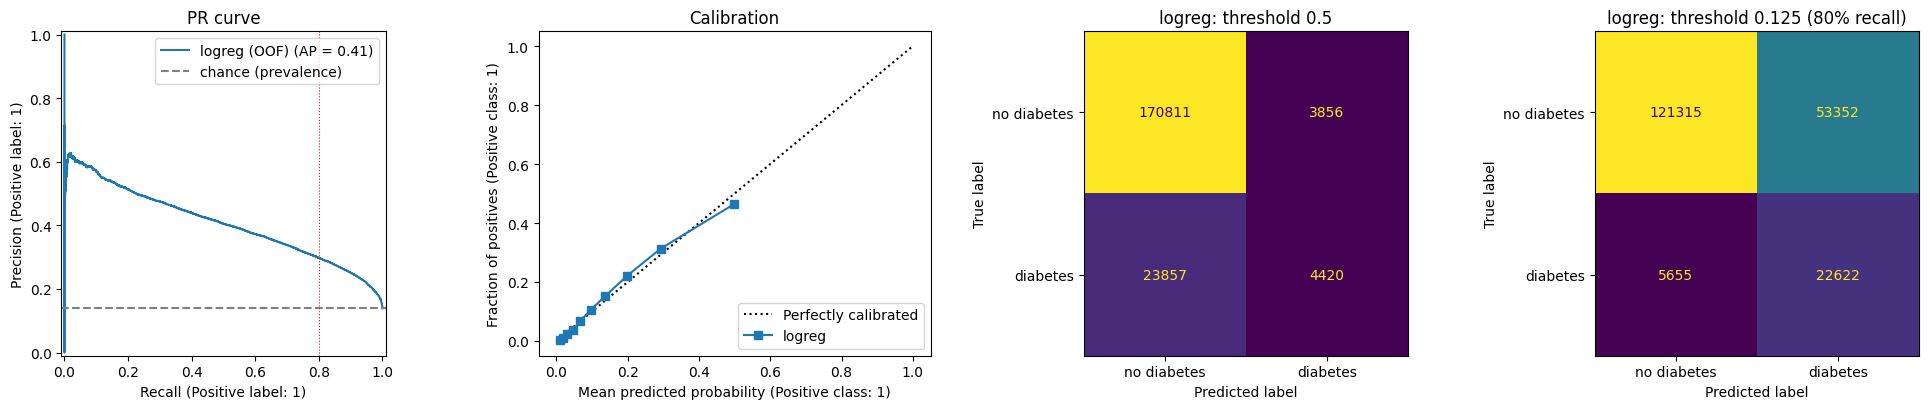

In [23]:
P = oof["logreg"]
def operating_point(y_bin, score, target=0.80):
    p, r, t = precision_recall_curve(y_bin, score)
    i = np.where(r[:-1] >= target)[0].max()
    return dict(threshold=t[i], recall=r[i], precision=p[i], share_flagged=(score >= t[i]).mean())

op80 = operating_point(y_dev, P)
print("Operating point at 80% recall (pooled out-of-fold predictions; development estimate):")
display(pd.DataFrame({"logreg": op80, "logreg balanced": operating_point(y_dev, oof["logreg balanced"])}).T.round(3))

fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
PrecisionRecallDisplay.from_predictions(y_dev, P, ax=ax[0], name="logreg (OOF)")
ax[0].axhline(y_dev.mean(), color="gray", ls="--", label="chance (prevalence)")
ax[0].axvline(0.8, color="red", lw=0.8, ls=":"); ax[0].set_title("PR curve"); ax[0].legend(loc="upper right")
CalibrationDisplay.from_predictions(y_dev, P, n_bins=10, strategy="quantile", ax=ax[1], name="logreg")
ax[1].set_title("Calibration")
for a, (thr, ttl) in zip(ax[2:], [(0.5, "threshold 0.5"), (op80["threshold"], f"threshold {op80['threshold']:.3f} (80% recall)")]):
    cm = confusion_matrix(y_dev, P >= thr)
    ConfusionMatrixDisplay(cm, display_labels=["no diabetes", "diabetes"]).plot(ax=a, colorbar=False, values_format="d")
    a.set_title(f"logreg: {ttl}")
plt.tight_layout(); plt.show()

**Interpretation.**
- **PR curve.** Sits well above the chance line (0.139) at every recall level. At 80% recall (dotted line) the threshold is about 0.125 and 37.4% of respondents are flagged at 29.8% precision. Reaching 80% recall is expensive: most flagged respondents do not report diabetes.
- **Calibration.** The unweighted model's predicted probabilities track observed rates closely, but even the highest-risk decile has a mean predicted probability of only about 0.5, so the model identifies no group as clearly high risk; it ranks, with limited separation.
- **Threshold 0.5.** Finds only 4,423 of 28,277 respondents who report diabetes (recall 0.16) at 53% precision, so the default threshold is not a sensible operating point here.
- **Threshold at 80% recall.** Finds 22,622 of 28,277 (recall 0.80) but also flags 53,321 respondents who do not report diabetes (precision 0.30). The workload and the missed-case rate trade off sharply, and the PCP guide's use should set that trade-off explicitly.

### 7.6 Which question groups matter? Feature-group analysis (for the PCP guide)
Features are grouped by what a PCP would ask or look up. Two views, both with the unweighted logistic baseline and the same folds:
- **Ladder:** add groups in order from "cheap demographic questions" to "history and care contact", showing the marginal gain of each step.
- **Drop-one:** remove a single group from the full model.

These are **associations in predictive accuracy**, not evidence that a question or test *causes* better detection. Care-contact and known-condition groups may reflect that a diagnosis already happened (Section 5).

In [24]:
GROUPS = {
    "demographics":        ["Age", "Sex", "Education", "Income"],
    "lifestyle":           ["Smoker", "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump"],
    "body (BMI)":          ["BMI"],
    "self-rated function": ["GenHlth", "MentHlth", "PhysHlth", "DiffWalk"],
    "known conditions":    ["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack"],
    "care contact":        ["CholCheck", "AnyHealthcare", "NoDocbcCost"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(feature_cols), "groups must partition the 21 features"

KEEP = ["PR-AUC", "Prec@80%rec", "log loss"]
full_res = cv_res["logreg"]
ladder_rows, cols_so_far = [], []
for g, cols in GROUPS.items():
    cols_so_far = cols_so_far + cols
    r = full_res if len(cols_so_far) == 21 else run_cv(LogisticRegression(max_iter=1000), cols_so_far)[0]
    ladder_rows.append(("+ " + g, len(cols_so_far), *r[KEEP].mean().values))
ladder = pd.DataFrame(ladder_rows, columns=["step", "n features"] + KEEP).set_index("step")

drop_rows = []
for g, cols in GROUPS.items():
    keep_cols = [c for c in feature_cols if c not in cols]
    r = run_cv(LogisticRegression(max_iter=1000), keep_cols)[0]
    drop_rows.append(("- " + g, len(keep_cols), *r[KEEP].mean().values))
drop = pd.DataFrame(drop_rows, columns=["step", "n features"] + KEEP).set_index("step")
full_row = pd.DataFrame([("all 21", 21, *full_res[KEEP].mean().values)], columns=["step", "n features"] + KEEP).set_index("step")

print("LADDER (cumulative):"); display(ladder.round(3))
print("DROP-ONE (vs all 21):"); display(pd.concat([full_row, drop]).round(3))

LADDER (cumulative):


,n features,PR-AUC,Prec@80%rec,log loss
step,,,,
+ demographics,4,0.241,0.205,0.375
+ lifestyle,9,0.256,0.212,0.370
+ body (BMI),10,0.322,0.243,0.351
+ self-rated function,14,0.367,0.279,0.333
+ known conditions,18,0.404,0.296,0.320
+ care contact,21,0.406,0.298,0.319


DROP-ONE (vs all 21):


,n features,PR-AUC,Prec@80%rec,log loss
step,,,,
all 21,21,0.406,0.298,0.319
- demographics,17,0.401,0.285,0.325
- lifestyle,16,0.403,0.296,0.320
- body (BMI),20,0.374,0.283,0.329
- self-rated function,17,0.377,0.279,0.330
- known conditions,17,0.369,0.282,0.331
- care contact,18,0.404,0.296,0.320


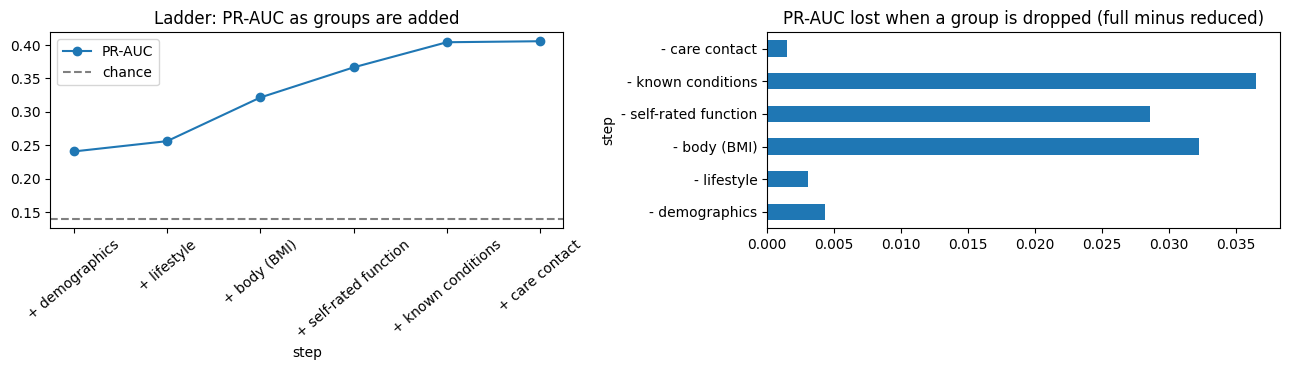

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ladder["PR-AUC"].plot(marker="o", ax=ax[0])
ax[0].axhline(y_dev.mean(), color="gray", ls="--", label="chance"); ax[0].legend()
ax[0].set_title("Ladder: PR-AUC as groups are added"); ax[0].tick_params(axis="x", rotation=40)
(full_row["PR-AUC"].iloc[0] - drop["PR-AUC"]).plot.barh(ax=ax[1], title="PR-AUC lost when a group is dropped (full minus reduced)")
plt.tight_layout(); plt.show()

**Ladder.** PR-AUC is 0.241 with four demographic questions alone (chance 0.139), rises slightly with five lifestyle questions (+0.015, close to fold noise), jumps when BMI is added (+0.066), then rises with self-rated function (+0.045) and known conditions (+0.037); care contact adds almost nothing (+0.002).

**Drop-one.** Removing known conditions costs the most (PR-AUC 0.406 to 0.369), then BMI (0.374) and self-rated function (0.377). Removing lifestyle (0.403), care contact (0.404) or demographics (0.402) costs little in PR-AUC, although dropping demographics lowers precision at 80% recall from 0.298 to 0.284, about as much as dropping BMI (0.283), function (0.278) or known conditions (0.282).

**Reading for the PCP guide, with caveats.** In this sample the most informative additions beyond age and sex are BMI, a general-health and functioning check, and history of high blood pressure, cholesterol, stroke and heart disease. Lifestyle answers add little once those are known. Care contact adds nothing *given the other groups*, even though CholCheck has the largest marginal association (Section 4.3), because it overlaps with the known-conditions group (people who were checked are the people who were told).


### 7.7 Fitted coefficients (association, not causation)
Coefficients are from the first CV fold's model so no extra fit on the full development set is introduced. Standardized numeric columns: per 1 SD; binary: per yes versus no. Log-odds of reported diabetes.

In [26]:
m0 = fitted["logreg"][0]
names = [n.split("__", 1)[1] for n in m0.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(m0.named_steps["clf"].coef_[0], index=names, name="log-odds").sort_values(ascending=False)
pd.DataFrame({"log-odds": coef, "odds ratio": np.exp(coef)}).round(2)

,log-odds,odds ratio
CholCheck,1.23,3.41
HighBP,0.77,2.16
GenHlth,0.58,1.78
HighChol,0.56,1.75
BMI,0.40,1.50
Age,0.37,1.44
Sex,0.26,1.29
HeartDiseaseorAttack,0.23,1.26
Stroke,0.14,1.15
DiffWalk,0.14,1.15


**Reading** (fold-1 model; log-odds of reported diabetes). The largest positive coefficients are CholCheck (1.27, odds ratio 3.6), HighBP (0.77, 2.2), GenHlth (0.58 per SD, 1.8), HighChol (0.56, 1.8), BMI (0.40 per SD, 1.5), Age (0.37 per SD, 1.4) and Sex male (0.26, 1.3). HvyAlcoholConsump is the largest negative (-0.77, odds ratio 0.46). Lifestyle items (Smoker, PhysActivity, Fruits, Veggies) are all near zero once the others are in the model.

**Caution.** The negative heavy-alcohol term is likely reverse causation or selection, and CholCheck is largely a care-contact marker. They are not risk factors to act on.

## 9. Validation design and generalization (15 pts)

### 9.1 What "unseen" means, and what is not demonstrated
- **Claim tested.** Performance and associations for **new respondents drawn from the same survey wave and sampling process**, assuming respondents are approximately independent and identically distributed. A random stratified partition matches that claim because the file has no group, time, or location column to hold out.
- **Not demonstrated.**
  1. Performance in a later year or a different data collection method.
  2. Performance in clinical populations or on individual patients.
  3. Detection of **undiagnosed** diabetes or prediction of **future** diabetes (the label is reported current diagnosis).
  4. Any statement about prediabetes (it is not separable in this data).


### 9.2 Partition procedure
$$\mathcal D=\mathcal D_{train}\cup\mathcal D_{val}\cup\mathcal D_{test},\qquad \mathcal D_a\cap\mathcal D_b=\emptyset\ \ (a\ne b)$$

1. Assert every `ID` is unique. No rows are dropped; identical answers from different IDs are treated as different respondents.
2. **Test set.** 20% of all rows, stratified on the target, seed `5040`. Locked.
3. **Development set** (80%): 5-fold stratified cross-validation, `shuffle=True`, seed `5040`. Each fold yields one training part and one validation part of the development set.
4. Row-disjointness does not guarantee independence if respondents repeat; no person, household, or state identifiers exist, so grouping is impossible and independence is assumed.

In [27]:
sizes = pd.DataFrame({
    "n": [len(df), len(dev), len(test)],
    "diabetes share": [d[TARGET].mean() for d in (df, dev, test)],
    "n diabetes": [int(d[TARGET].sum()) for d in (df, dev, test)],
}, index=["all rows", "development", "test (locked)"])
display(sizes.round(4))

# partition checks
splits = list(cv.split(X_dev, y_dev))
assert all(not (set(tr) & set(va)) for tr, va in splits), "train/val overlap inside a fold"
all_va = np.concatenate([va for _, va in splits])
assert len(all_va) == len(dev) and len(set(all_va)) == len(dev), "validation parts must tile dev exactly once"
assert not (set(dev["ID"]) & set(test["ID"])), "an ID is in both dev and test"
print("IDs shared by dev and test: 0")
prof = feature_cols + [TARGET]
shared = test.merge(dev[prof].drop_duplicates(), on=prof, how="inner")
print(f"test rows whose answers+label also occur in dev (different respondents): {len(shared):,} ({len(shared)/len(test):.1%})")

pd.DataFrame([(k, len(tr), len(va), y_dev.iloc[tr].mean(), y_dev.iloc[va].mean(), int(y_dev.iloc[va].sum()))
              for k, (tr, va) in enumerate(splits, 1)],
             columns=["fold", "n_train", "n_val", "prev_train", "prev_val", "n_diabetes_val"]).round(4)

,n,diabetes share,n diabetes
all rows,253680,0.1393,35346
development,202944,0.1393,28277
test (locked),50736,0.1393,7069


IDs shared by dev and test: 0
test rows whose answers+label also occur in dev (different respondents): 6,416 (12.6%)


,fold,n_train,n_val,prev_train,prev_val,n_diabetes_val
0,1,162355,40589,0.1393,0.1393,5655
1,2,162355,40589,0.1393,0.1393,5655
2,3,162355,40589,0.1393,0.1393,5656
3,4,162355,40589,0.1393,0.1393,5656
4,5,162356,40588,0.1393,0.1393,5655


**Interpretation.** The development set, test set and every validation fold keep the same diabetes share (13.93%). 

### 9.3 Fold contract and evidence that fitted state is per fold
In every fold $k$: $S_{tr,k}\to(\hat\eta_k,\hat\theta_k)$ and $S_{val,k}\to\mathrm{Eval}(\hat M_k)$. Each fold uses a fresh `clone` of the pipeline; no state is shared. The table shows the fitted scaler means differing slightly by fold (they were learned from different training rows) and from the all-development mean, which would be the *leaked* value if the scaler were fit before the split.

In [28]:
state = pd.DataFrame({f"fold {i}": m.named_steps["prep"].named_transformers_["num"].named_steps["scale"].mean_
                      for i, m in enumerate(fitted["logreg"], 1)}, index=NUMERIC)
state["all-dev mean (NOT used)"] = X_dev[NUMERIC].mean().values
state.round(4)

,fold 1,fold 2,fold 3,fold 4,fold 5,all-dev mean (NOT used)
BMI,28.3690,28.3715,28.3848,28.3812,28.3764,28.3766
MentHlth,3.1832,3.1767,3.1725,3.1729,3.1827,3.1776
PhysHlth,4.2412,4.2517,4.2566,4.2386,4.2490,4.2474
Age,8.0333,8.0302,8.0355,8.0282,8.0303,8.0315
GenHlth,2.5109,2.5123,2.5127,2.5095,2.5135,2.5118
Education,5.0486,5.0478,5.0464,5.0491,5.0466,5.0477
Income,6.0558,6.0545,6.0507,6.0562,6.0510,6.0536


### 9.4 Survey design and weights
BRFSS is a complex, stratified, weighted survey: each respondent represents a different number of adults and weights correct for unequal selection and nonresponse. This file contains **no weight, strata, or PSU column**


## 10. Workflow Canvas v2 and reproducibility (5 pts)

### 10.1 Canvas v2
Chain: decision/problem → observation → measurement and features → preparation → baseline learning → model output → validation → metric(s) → intended use.
Composition: $M=M_K\circ\cdots\circ M_1$, here $\hat M=f_{\hat\theta}\circ T_{\hat\eta}\circ \text{select}$.

Each stage below is marked **fixed** (no data-dependent state) or **learned** (state estimated from data), with its stored state and the sample it is fitted on.

- **Decision / problem.** Which survey questions and tests help a PCP anticipate reported diabetes? This is a research guide, not a diagnosis tool.
- **Observation.** One BRFSS respondent.
- **Measurement and features.** 21 self-reported answers; the label is reported diabetes. Fixed.
- **Cleaning.** Engineer `diabetes_reported`, drop `ID` and `Diabetes_binary` from the features, and assert that `ID` is unique. No rows are dropped. Fixed; no stored state.
- **Preparation.** Median imputation (a safeguard, since nothing is missing), standardization of the 7 numeric and ordinal columns, and binary columns passed through unchanged. **Learned**; the stored state is the training medians and $\hat\mu_j,\hat\sigma_j$, fitted on the training fold only.
- **Baseline learning.** Binary logistic regression, with a dummy classifier as the floor. **Learned**; the stored state is $\hat\theta$ (coefficients and intercept), fitted on the training fold only.
- **Model output.** $\hat p=\Pr(y=1\mid x)$, a probability. It is thresholded only for the confusion matrices.
- **Validation.** 20% stratified test set locked away; 5-fold stratified CV on the development set. A fixed design; the only state is the fold indices (seed 5040).
- **Metrics.** PR-AUC, precision at 80% recall, log loss, Brier score and calibration. The one stored value is the 80%-recall threshold, chosen on out-of-fold validation predictions, so it is a development estimate.
- **Intended use.** Prioritize survey questions and tests in a PCP guide. Not a diagnosis.

**Claim tested by validation.** The baseline ranks new respondents from the same survey wave better than prevalence alone, with the reported scores, under the exchangeability assumption.
**Risks and evidence from this audit.** Target contents (prediabetes in the reference class; 2.4), identical answer profiles with conflicting labels (3.2), self-report error, care-contact proxies (7.6), missing survey weights (9.4), unknown survey year (1.3).
**Outstanding decisions.** Ordinal handling (numeric vs one-hot); model class for the next milestone; whether a three-class target from another source is needed; whether identical answer profiles need special handling (kept as distinct respondents here); how to treat the 80%-recall threshold in the final evaluation; survey weights.

### 10.2 How to rerun
1. Create an environment and install `requirements.txt`: `pip install -r requirements.txt`.
2. Open this notebook and choose *Restart kernel and Run All*. The first run downloads the data from UCI via `ucimlrepo` and caches it in `data/` (git-ignored). No other source is used.
3. All randomness uses `SEED = 5040`; the partition and fold assignment are deterministic.
4. Runtime is a few minutes (CV of 15 model configurations).
5. Do not commit `data/`. The data are public-use, but are not redistributed here.

Library versions used are printed in Section 0.1 and listed in `requirements.txt`.

## 11. Final reflection

**What changed after Milestone 1 feedback.**
- The intended use changed from a screening tool for people *before* diagnosis to a **research guide for PCPs** on which questions to ask and which tests to consider, with prior medical contact accepted as part of the inputs. The label records reported diagnosis at survey time and nothing here supports undiagnosed or future-risk claims.
- The target is **reported diabetes** from the UCI binary label, not the prediabetes-plus-diabetes class planned in Milestone 1: an external cross-check showed prediabetes is coded 0, and UCI data cannot separate it.
- The notation, a fixed/learned operator table, a leakage-safe pipeline, prevalence-aware metrics tied to the use, and an explicit "not demonstrated" list were added.

**What the data audit revealed.**
- UCI's description of the label does not match the file: `Diabetes_binary = 1` is diabetes only.
- No NaN or out-of-range value. `ID` is unique, but 9.5% of rows share all 21 answers and the label with another respondent, and 1,566 answer profiles appear with both labels.
- No survey weights, strata or PSU, and an unresolved survey year.
- The strongest univariate signals are care-contact and comorbidity variables.

**Assumptions challenged.**
- "Prediabetes is in the positive class" was false, and cannot be fixed with UCI data alone.
- "Features are available at the screening time" no longer applies in the same way once the use becomes a PCP research guide.
- Treating the ordinal codes as linear holds for GenHlth, BMI and Income but not fully for Age.
- "Class weighting helps" did not hold: ranking was unchanged and probabilities were badly distorted.
- Identical answers do not mean the same person: dropping those rows would have removed real respondents and shifted prevalence, so no rows are dropped and `ID` is checked instead.

**What the baseline and validation show, and do not show.**
- Show: reported diabetes is discriminated well above chance (PR-AUC 0.41 versus 0.14; ROC-AUC 0.82) from 21 self-reported answers, consistently across folds; BMI, general health and functioning, and known conditions carry most of the signal; reaching 80% recall means flagging about 37% of respondents at 30% precision.
- Do not show: anything about prediabetes, performance in later years or clinical populations, detection of undiagnosed diabetes, causal effects of any question or test, population-weighted results, subgroup performance, or an estimate on the locked test set.

**Next evidence needed.**
1. Survey year, question wording and the meaning of `ID` from the codebook, and whether design variables can be recovered.
2. A decision on whether a three-class target from another source is needed.
3. Confirmation that `ID` identifies a respondent, and a comparison of ordinal coding.
4. A stronger candidate model family and threshold selection nested inside cross-validation (next milestone).
5. Subgroup checks before any claim about use with patients.